# Single Fidelity MLP Comparison

This workbook trains `SurrogateModels.mfsnn.MLPNetwork` over 2D, 4D, 6D, 8D, and 10D analytical test functions, sweeping sample count to compare accuracy and cost -- same structure as `SingleFidelityComparison_KAN.ipynb` and `SingleFidelityComparison_Kriging.ipynb`.

Helper functions live in `examples/single_fidelity_nn_helpers.py`.

(Note: there's a pre-existing `SingleFidelityComparison_NN.ipynb` in this folder from earlier exploration -- it predates `single_fidelity_nn_helpers.py` and has its own inline, duplicated version of these functions plus a handful of ad hoc exploratory models. Left untouched; this notebook is a separate, from-scratch build using the shared helper module.)

**Sample ranges:** unlike the Kriging notebook, these reuse the *same* ranges as the KAN notebook (up to `n=4000` for 8D) rather than cut-down ones -- `MLPNetwork`'s AdamW/epoch-based training scales far more gracefully with sample count than Kriging's per-iteration Cholesky decomposition does. Spot-checked at 8D (the most expensive case elsewhere): `n=100` -> 11s, `n=1000` -> 22s, `n=4000` -> 78s, nothing like Kriging's multi-hour blowup at similar `n`.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from examples import single_fidelity_nn_helpers as nn_helpers


### 2-Dimensional Dataset

In [2]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = nn_helpers.create_test_points(my_function, n=1000)


Run 2D :: seed 0 :: points 50 :: error 1.51442806821805 :: train_time 155.04459469999983 
Run 2D :: seed 0 :: points 150 :: error 0.1294133919537072 :: train_time 151.74808490000032 
Run 2D :: seed 0 :: points 250 :: error 0.0407335333915037 :: train_time 149.8526310999996 
Run 2D :: seed 0 :: points 350 :: error 0.03204682238711944 :: train_time 149.4851223000005 
Run 2D :: seed 0 :: points 450 :: error 0.024032016934812078 :: train_time 163.8913107999997 
Run 2D :: seed 0 :: points 550 :: error 0.012640668425107832 :: train_time 154.1463502000006 
Run 2D :: seed 0 :: points 650 :: error 0.01245874956189839 :: train_time 150.86252820000027 
Run 2D :: seed 0 :: points 750 :: error 0.014005085567672394 :: train_time 152.01882419999947 
Run 2D :: seed 0 :: points 850 :: error 0.010002260837015295 :: train_time 153.80454110000028 
Run 2D :: seed 0 :: points 950 :: error 0.009994873921554962 :: train_time 151.30386739999994 
Run 2D :: seed 0 :: points 1050 :: error 0.012548981581352484 :: 

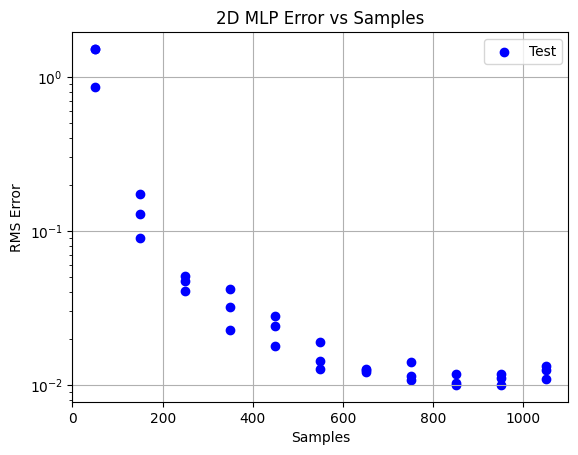

In [3]:
points_2d = []
model_error_2d = []
training_time_2d = []
evaluation_time_2d = []
points_2d, model_error_2d, evaluation_time_2d, training_time_2d = nn_helpers.generate_nn_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=50,
    sample_high=1051,
    step_size=100,
    seeds=3,
    points=points_2d,
    model_error=model_error_2d,
    training_time=training_time_2d,
    evaluation_time=evaluation_time_2d,
    hidden_layer_size=[30, 30, 10],
    learning_rate=1e-4,
    weight_decay=1e-6,
    epochs=30000,
    output_file="nn_model_comparison_2d.csv",
)
ax = nn_helpers.plot_error_measure(points_2d, model_error_2d, "2D MLP Error vs Samples")
nn_helpers.save_plot(ax, "2D_sweep_mlp")
plt.show()


### 4-Dimensional Dataset

In [4]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = nn_helpers.create_test_points(my_function, n=1000)


Run 4D :: seed 0 :: points 1000 :: error 1.471332612977507 :: train_time 150.00305900000058 :: evaluation_time 0.0012175000010756776


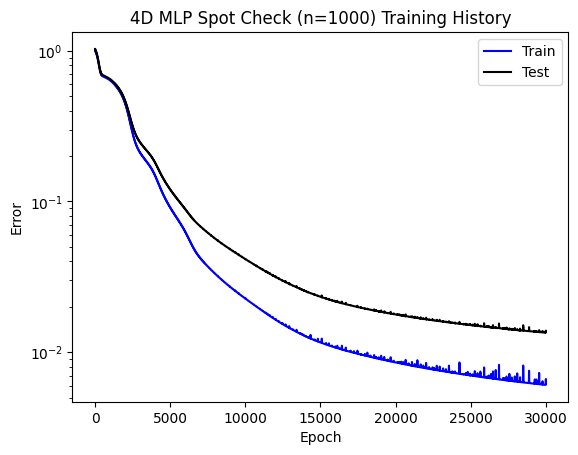

In [5]:
# Spot check: single n=1000 run with the same settings as the 4D sweep below
model_4d_check, error_4d_check, train_time_4d_check, eval_time_4d_check = nn_helpers.generate_nn_model(
    key,
    my_function,
    n=1000,
    seed=0,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[30, 30, 10],
    learning_rate=1e-4,
    weight_decay=1e-6,
    epochs=30000,
)
model_4d_check.plot_training_error("4D MLP Spot Check (n=1000) Training History")
plt.show()

Run 4D :: seed 0 :: points 100 :: error 14.16795301009513 :: train_time 152.85763829999996 
Run 4D :: seed 0 :: points 200 :: error 7.186893622929317 :: train_time 149.786425100001 
Run 4D :: seed 0 :: points 300 :: error 5.92985163743375 :: train_time 149.35359470000003 
Run 4D :: seed 0 :: points 400 :: error 3.3409752589307478 :: train_time 150.39595330000157 
Run 4D :: seed 0 :: points 500 :: error 5.033693582950261 :: train_time 150.27773949999937 
Run 4D :: seed 0 :: points 600 :: error 2.4276941380037758 :: train_time 153.29211570000007 
Run 4D :: seed 0 :: points 700 :: error 1.8737788866965368 :: train_time 150.60657549999996 
Run 4D :: seed 0 :: points 800 :: error 1.741624520084279 :: train_time 149.64362580000125 
Run 4D :: seed 0 :: points 900 :: error 1.6687483323547587 :: train_time 153.712285900001 
Run 4D :: seed 0 :: points 1000 :: error 1.3685727090802133 :: train_time 152.19628179999927 
Run 4D :: seed 1 :: points 100 :: error 22.376494083485607 :: train_time 149.84

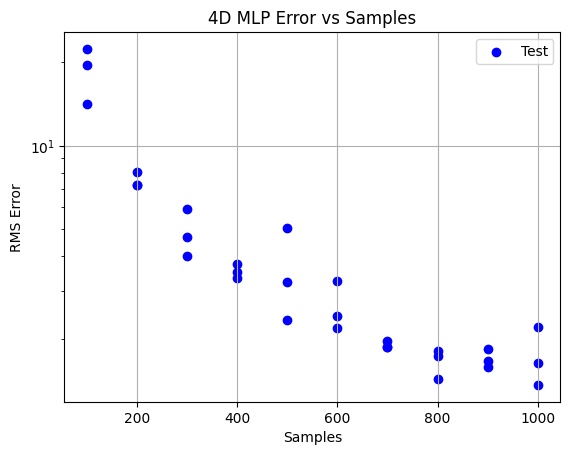

In [6]:
points_4d = []
model_error_4d = []
training_time_4d = []
evaluation_time_4d = []
points_4d, model_error_4d, evaluation_time_4d, training_time_4d = nn_helpers.generate_nn_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=100,
    sample_high=1001,
    step_size=100,
    seeds=3,
    points=points_4d,
    model_error=model_error_4d,
    training_time=training_time_4d,
    evaluation_time=evaluation_time_4d,
    hidden_layer_size=[30, 30, 10],
    learning_rate=1e-4,
    weight_decay=1e-6,
    epochs=30000,
    output_file="nn_model_comparison_4d.csv",
)
ax = nn_helpers.plot_error_measure(points_4d, model_error_4d, "4D MLP Error vs Samples")
nn_helpers.save_plot(ax, "4D_sweep_mlp")
plt.show()


### 6-Dimensional Dataset

In [7]:
key = "6D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = nn_helpers.create_test_points(my_function, n=1000)


Run 6D :: seed 0 :: points 100 :: error 0.36291628019499506 :: train_time 152.64530139999988 
Run 6D :: seed 0 :: points 300 :: error 0.15789375450330548 :: train_time 150.5384785999995 
Run 6D :: seed 0 :: points 500 :: error 0.12630734705541022 :: train_time 152.06678509999983 
Run 6D :: seed 0 :: points 700 :: error 0.08869307695562618 :: train_time 151.0833126000016 
Run 6D :: seed 0 :: points 900 :: error 0.08801419980025457 :: train_time 149.44881239999995 
Run 6D :: seed 0 :: points 1100 :: error 0.08829015967543749 :: train_time 152.33254080000006 
Run 6D :: seed 0 :: points 1300 :: error 0.07791694270040653 :: train_time 152.33403829999952 
Run 6D :: seed 0 :: points 1500 :: error 0.04834470488493589 :: train_time 150.13618889999998 
Run 6D :: seed 0 :: points 1700 :: error 0.05314032911032132 :: train_time 151.36647230000017 
Run 6D :: seed 0 :: points 1900 :: error 0.04670126141917619 :: train_time 149.1368614999992 
Run 6D :: seed 1 :: points 100 :: error 0.3550227556584646

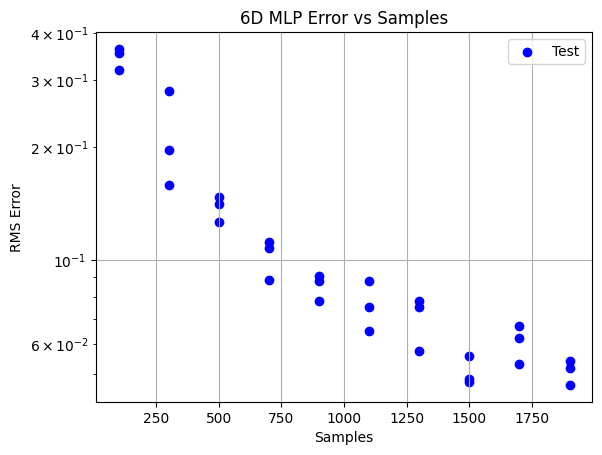

In [8]:
points_6d = []
model_error_6d = []
training_time_6d = []
evaluation_time_6d = []
points_6d, model_error_6d, evaluation_time_6d, training_time_6d = nn_helpers.generate_nn_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=100,
    sample_high=2001,
    step_size=200,
    seeds=3,
    points=points_6d,
    model_error=model_error_6d,
    training_time=training_time_6d,
    evaluation_time=evaluation_time_6d,
    hidden_layer_size=[30, 30, 10],
    learning_rate=1e-4,
    weight_decay=1e-6,
    epochs=30000,
    output_file="nn_model_comparison_6d.csv",
)
ax = nn_helpers.plot_error_measure(points_6d, model_error_6d, "6D MLP Error vs Samples")
nn_helpers.save_plot(ax, "6D_sweep_mlp")
plt.show()


### 8-Dimensional Dataset

In [14]:
key = "8D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = nn_helpers.create_test_points(my_function, n=1000)


Run 8D :: seed 0 :: points 100 :: error 3.075259838298047 :: train_time 147.67865499999607 
Run 8D :: seed 0 :: points 500 :: error 0.3158206396698281 :: train_time 151.669427300003 
Run 8D :: seed 0 :: points 900 :: error 0.14883768379951004 :: train_time 148.85412279999582 
Run 8D :: seed 0 :: points 1300 :: error 0.15034982407204955 :: train_time 148.95977019999555 
Run 8D :: seed 0 :: points 1700 :: error 0.11340889182447672 :: train_time 151.07925570000225 
Run 8D :: seed 0 :: points 2100 :: error 0.08065078158566866 :: train_time 149.63872830000037 
Run 8D :: seed 0 :: points 2500 :: error 0.11778866679348318 :: train_time 161.36974510000437 
Run 8D :: seed 0 :: points 2900 :: error 0.11767477127985634 :: train_time 162.7047900000034 
Run 8D :: seed 0 :: points 3300 :: error 0.05110095042706083 :: train_time 158.31276179999986 
Run 8D :: seed 0 :: points 3700 :: error 0.08254750404892389 :: train_time 161.05543949999992 
Run 8D :: seed 1 :: points 100 :: error 3.0969984204467753 

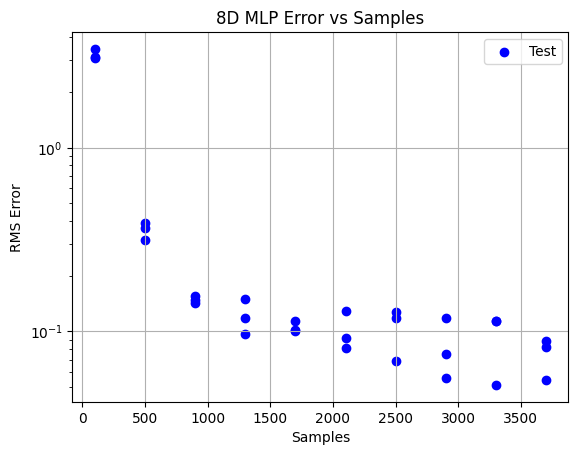

In [15]:
points_8d = []
model_error_8d = []
training_time_8d = []
evaluation_time_8d = []
points_8d, model_error_8d, evaluation_time_8d, training_time_8d = nn_helpers.generate_nn_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=100,
    sample_high=4000,
    step_size=400,
    seeds=3,
    points=points_8d,
    model_error=model_error_8d,
    training_time=training_time_8d,
    evaluation_time=evaluation_time_8d,
    hidden_layer_size=[30, 30, 10],
    learning_rate=1e-4,
    weight_decay=1e-6,
    epochs=30000,
    output_file="nn_model_comparison_8d.csv",
)
ax = nn_helpers.plot_error_measure(points_8d, model_error_8d, "8D MLP Error vs Samples")
nn_helpers.save_plot(ax, "8D_sweep_mlp")
plt.show()


### 10-Dimensional Dataset

In [11]:
key = "10D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = nn_helpers.create_test_points(my_function, n=1000)


Run 10D :: seed 0 :: points 100 :: error 5.19290445264325 :: train_time 151.34031120000145 
Run 10D :: seed 0 :: points 200 :: error 1.5702608163350704 :: train_time 149.00219079999806 
Run 10D :: seed 0 :: points 300 :: error 0.5413488558573251 :: train_time 152.2255933000015 
Run 10D :: seed 0 :: points 400 :: error 0.38961417134564963 :: train_time 150.07068159999835 
Run 10D :: seed 0 :: points 500 :: error 0.28911075552144266 :: train_time 149.1480212000024 
Run 10D :: seed 0 :: points 600 :: error 0.22922576522106147 :: train_time 151.90100410000014 
Run 10D :: seed 0 :: points 700 :: error 0.200418071223894 :: train_time 149.99617969999963 
Run 10D :: seed 0 :: points 800 :: error 0.18789951514485517 :: train_time 151.9086838999974 
Run 10D :: seed 0 :: points 900 :: error 0.15334559129299705 :: train_time 151.0980965000017 
Run 10D :: seed 0 :: points 1000 :: error 0.13997643176524296 :: train_time 151.12519789999715 
Run 10D :: seed 0 :: points 1100 :: error 0.1369705417665455

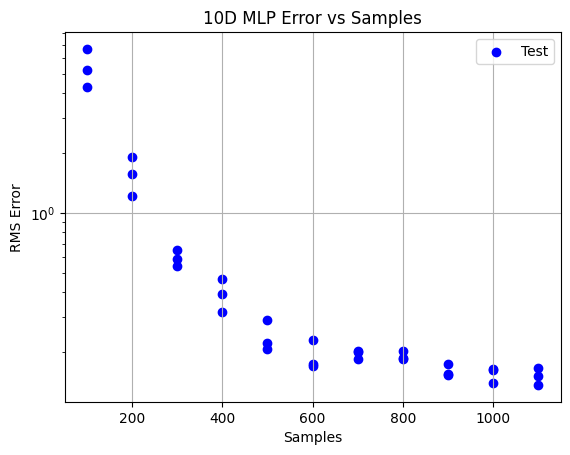

In [12]:
points_10d = []
model_error_10d = []
training_time_10d = []
evaluation_time_10d = []
points_10d, model_error_10d, evaluation_time_10d, training_time_10d = nn_helpers.generate_nn_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=100,
    sample_high=1101,
    step_size=100,
    seeds=3,
    points=points_10d,
    model_error=model_error_10d,
    training_time=training_time_10d,
    evaluation_time=evaluation_time_10d,
    hidden_layer_size=[20, 20, 20],
    learning_rate=1e-4,
    weight_decay=1e-6,
    epochs=30000,
    output_file="nn_model_comparison_10d.csv",
)
ax = nn_helpers.plot_error_measure(points_10d, model_error_10d, "10D MLP Error vs Samples")
nn_helpers.save_plot(ax, "10D_sweep_mlp")
plt.show()
